# COSYNE abstract figure — one dense summary of the project

One 180 mm figure, panels in the order of the story:

| | panel | drawn by |
|---|---|---|
| a | task diagram (space for the Inkscape drawing) | here |
| b | what the states are: paw states' vigor and left − right laterality, and the whisking and licking states' z-scored whisker motion energy and lick count | `fig_segmentation` `draw_D` + here (from the states files) |
| c | the three segmentations (paw, whisking, licking) over a 20 s snippet | `fig_segmentation` `draw_F` |
| d | how the states are used across the trial: occupancy per epoch, paw states and whisking / licking | `fig_segmentation` `draw_G` (its panel e) |
| e | mouse and lab identification from syllables, the raw signal and trial measures | `vigor/zscore/ci_segmentation_vs_raw.csv` + `ci_trial_measures.csv` (same protocol) |
| f | mice in the LD1–LD2 plane, with the LD1 colour bar shared by the figure | `fig_ld1` `draw_A` |
| g | syllable use along LD1 | `fig_ld1` `draw_B` |
| h | trial-level correlates of LD1 | `fig_ld1` panel C data |
| i | engagement: GLM-HMM weights, psychometric and chronometric curves per state; state switches and the engaged posterior (log ratio) vs LD1 | `fig_engagement` `draw_B`, `draw_C`, `corr_ax` |
| j | neural correlates, compressed: per metric, the time course by LD1 tercile beside its row of the effect map | `lda1_neural_metrics` |
| k | individuality across learning: where the timepoints sit in training (example mice), and the proficient LDA identifying the mouse at each | `learning_individuality/dataset_timepoints_overview.ipynb` panel A; numbers from `lda_sweep_timepoints.ipynb` |

**How the panels are drawn.** Each source notebook's code cells (everything before its assembly cell) are executed into their own namespace, and its `draw_*` functions are called here — so a panel is literally the same code as in its own figure, nothing copied. Their single-panel previews are suppressed. This makes the notebook slow the first time (fig_segmentation, fig_ld1 and fig_engagement each run; fig_ld1 caches its identification results).

**Consistency notes.**
* LD1 is the current LDA file everywhere, **including the neural panel h**: the cached neural tables carry an older LD1 (r = −0.88, opposite sign), which is replaced before the tests are rerun here — so h's numbers are not `fig_neural`'s rows a–c.
* Panel e: all six bars use one protocol (`vigor/lda/zscore_cost`: shrinkage LDA 0.5, ≤ 3 sessions per mouse; mouse ID leave-one-session-out, lab ID with the test mouse's sessions all held out; 95 % CI bootstrap over mice). Syllables / raw: `ci_segmentation_vs_raw.py` (260 sessions, 56 mice); trial measures: `ci_trial_measures.py` (10 session-level task measures, 234 sessions, 55 mice).
* Panel k's accuracies are **transcribed** from the stored output of `lda_sweep_timepoints.ipynb` (run on the other machine; its syllable files are not on this one). That analysis uses its own syllable set (`left_paw_wheel`, k = 8), not the 360-feature set of panels e–j. Rerun it and update `TIMEPOINTS_RESULT` if it changes.

**Inputs on this machine.** The source notebooks need data that lives on the analysis machine: `data/8_k_10_bin_syllables_02-10-2026`, `data/states_files/`, `data/session_trial_meta_19-08-2026`, `vigor/paw_bias/state_profiles_uniform.csv`. Where a source notebook cannot run here, its panels are filled with the **stored output image** of that panel's own preview cell in the source notebook (marked 'preview'), so the layout can be checked without the data; run the notebook on the analysis machine for the real, vector figure.

In [1]:
import sys, pathlib, re, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize
import matplotlib as mpl

FIGDIR = pathlib.Path.cwd().resolve()
while not (FIGDIR / 'fig_layout.py').exists() and FIGDIR != FIGDIR.parent:
    FIGDIR = FIGDIR / 'figure_generation' if (FIGDIR / 'figure_generation').exists() else FIGDIR.parent
PI = FIGDIR.parent
for p in [str(PI), str(PI / 'neural'), str(FIGDIR)]:
    if p not in sys.path:
        sys.path.insert(0, p)
# the LDA file was pickled under numpy 2; under numpy 1 its module paths need aliasing to unpickle
try:
    import numpy._core.numeric  # noqa: F401
except ModuleNotFoundError:
    import numpy.core.numeric, numpy.core.multiarray
    sys.modules['numpy._core.numeric'], sys.modules['numpy._core.multiarray'] = np.core.numeric, np.core.multiarray
import paper_style as ps
import fig_layout as fl
ps.use('paper')
FIG = 'cosyne_figure'
CACHE = FIGDIR / 'cache'

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Running the source notebooks

`load_panels` executes a notebook's code cells, in order, into a fresh namespace, stopping at its assembly cell (the one calling `fl.place_letters`). `plt.show` is replaced by a close for the duration, so the source notebooks' single-panel previews are not drawn here. `subs` patches a cell's source before it runs (here: fig_segmentation's snippet-picking embedding, which is not on this machine, and two example sessions instead of four).

In [2]:
import json

def load_panels(name, subs=None, stop_after=None, path=None, cwd=None):
    """The notebook's namespace, or None if its inputs are not on this machine (the panels it feeds are then
    drawn as labelled placeholders, so the layout can still be checked)."""
    try:
        return _load_panels(name, subs, stop_after, path, cwd)
    except (FileNotFoundError, OSError) as e:
        plt.show = _SHOW; plt.close('all'); ps.use('paper')
        print(f'{name}: NOT loaded -- missing input: {e}')
        return None

_SHOW = plt.show

def _load_panels(name, subs=None, stop_after=None, path=None, cwd=None):
    import os
    nb = json.load(open(path or FIGDIR / f'{name}.ipynb'))
    here = os.getcwd()
    if cwd:
        os.chdir(cwd)
    ns = {'__name__': f'cosyne_{name}'}
    show = _SHOW
    plt.show = lambda *a, **k: plt.close('all')
    try:
        for c in nb['cells']:
            if c['cell_type'] != 'code':
                continue
            src = ''.join(c['source'])
            if 'place_letters' in src or 'fig.savefig(path)' in src:
                break
            for a, b in (subs or {}).items():
                src = src.replace(a, b)
            exec(compile(src, f'{name}.ipynb', 'exec'), ns)
            if stop_after and stop_after in src:
                break
    finally:
        os.chdir(here)
        plt.show = show
        plt.close('all')
    ps.use('paper')
    print(f'{name}: loaded')
    return ns

import json
_emb = PI / 'clustering' / 'data_files' / 'mouse_LDA_5_bins_raw_shrink0.5_360_28-09-2026'
SEG_SUBS = {"N_EXAMPLES, MAX_MISSING = 4, 0.05": "N_EXAMPLES, MAX_MISSING = 2, 0.05"}
if not _emb.exists():   # the snippet-picking embedding of fig_segmentation is not on this machine: use the current one
    SEG_SUBS["clustering/data_files/mouse_LDA_5_bins_raw_shrink0.5_360_28-09-2026"] = \
        "clustering/data_files/mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026"
SEG = load_panels('fig_segmentation', subs=SEG_SUBS)
LD = load_panels('fig_ld1')
# the LD1 x LD2 plane needs only the LDA file: if fig_ld1 cannot run in full here, run it up to draw_A
LDA_NS = LD if LD is not None else load_panels('fig_ld1', stop_after='def draw_A')
ENG = load_panels('fig_engagement')
# k: where the timepoints sit in training (its panel A), from the learning-individuality notebook
TL = load_panels('dataset_timepoints_overview', path=PI / 'learning_individuality' / 'dataset_timepoints_overview.ipynb',
                 cwd=PI / 'learning_individuality', stop_after='def trajectory_panel',
                 subs={'SHOW_LEARNING_CURVE = True': 'SHOW_LEARNING_CURVE = False', 'N_MICE = 12': 'N_MICE = 6'})
ps.use_paw_states('uniform')

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


332 sessions, 101 mice, 206,879 trials
CSH_ZAD_029 064a7252, window 1502-1511 s


                 paw0   paw1   paw2   paw3   paw4   paw5   paw6   paw7  whisk  \
Pre-quiescence  0.221  0.517  0.087  0.050  0.068  0.033  0.019  0.006  0.500   
Quiescence      0.171  0.631  0.054  0.009  0.124  0.003  0.003  0.005  0.284   
Choice          0.102  0.152  0.224  0.177  0.136  0.133  0.070  0.006  0.699   
ITI             0.112  0.318  0.158  0.115  0.131  0.095  0.065  0.007  0.851   

                 lick  
Pre-quiescence  0.080  
Quiescence      0.041  
Choice          0.174  
ITI             0.483  
  CSH_ZAD_029      fece187f   1523 trials  0.0% missing bins
  NR_0027          0f77ca5d   1186 trials  0.0% missing bins


all trials: P(paw) = [0.154 0.404 0.134 0.092 0.11  0.064 0.036 0.006]


paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
fig_segmentation: loaded
paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
non-emerging metrics: nonemerging_session_metrics_29-09-2026.csv
260 sessions, 56 mice; between-mouse share LD1-3: [0.136 0.099 0.085]


...

state   disengaged  engaged
cx                         
0.0000       0.288    0.269
0.0625       0.248    0.207
0.1250       0.246    0.178
0.2500       0.197    0.159
1.0000       0.145    0.138


K=4 switches over the first 400 trials
mouse_name      244
lab             244
LD1             244
bouts_dis_0     244
bouts_dis_1     244
bouts_dis_2     244
bouts_dis_3     244
bouts_dis_4     244
bouts_dis_5     244
bouts_dis_6     244
bouts_eng_0     244
bouts_eng_1     244
bouts_eng_2     244
bouts_eng_3     244
bouts_eng_4     244
bouts_eng_5     244
bouts_eng_6     244
short_bouts     244
long_bouts      244
frac_engaged    244
log_ratio       244
entropy         244
p_stay_eng      244
p_stay_dis      228
switches        244
n_ee            244
n_ed            244
n_de            244
n_dd            244
p_easy          244
gain_23         231
gain_24         231
bpt_K2          231
switches_k4     231
session level (pearson, fdr_bh) -- the one drawn:
               measure    n       r       p   p_fdr  significant
key                                                             
D1        frac_engaged  244  0.0371  0.5640  0.5640        False
D2           log_ratio  244  0.2386 

                                     mouse_name    LD1  frac_engaged  mean_p_engaged  switches
eid                                                                                           
3663d82b-f197-4e8b-b299-7b803a155b84    CSHL052 -6.546         0.945           0.776      41.0
ae8787b1-4229-4d56-b0c2-566b61a25b77    NR_0027  4.571         0.945           0.871       2.0
low  LD1 third (n = 81 sessions, mean LD1 -5.3): P(E->E) 0.977, P(D->D) 0.813; mean bout: engaged 44, disengaged 5.3 trials
high LD1 third (n = 82 sessions, mean LD1 +4.8): P(E->E) 0.986, P(D->D) 0.874; mean bout: engaged 72, disengaged 7.9 trials
high / low:
 [[1.01 0.61]
 [0.67 1.08]]
high - low:
 [[ 0.009 -0.009]
 [-0.061  0.061]]
low  LD1 third, disengaged bouts / 400 trials: 1–2: 4.99, 3–5: 1.81, 6–10: 0.93, 11–20: 0.28, 21–50: 0.19, 51–100: 0.15, >100: 0.04
low  LD1 third, engaged    bouts / 400 trials: 1–2: 0.70, 3–5: 0.79, 6–10: 1.21, 11–20: 1.74, 21–50: 2.37, 51–100: 1.22, >100: 0.88
high LD1 third, dise

not saved (ps.SAVE_FIGURES is False): figures/timepoints_example_trajectories_poster_12-10-2026.png, figures/timepoints_example_trajectories_poster_12-10-2026.svg   -- ps.saving(True) to write, or pass save=True
paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
dataset_timepoints_overview: loaded


{'colors': ['#EDE8D8',
  '#BFB5C7',
  '#B688D8',
  '#A98605',
  '#84778F',
  '#9420CF',
  '#7C4702',
  '#3B2B1C'],
 'vigor_order': [0, 1, 2, 3, 4, 5, 6, 7],
 'lateral': {'left': [2, 5], 'right': [3, 6], 'symmetric': [0, 1, 4, 7]},
 'states_dir': 'data/paw_states_uniform_raw_sessionz',
 'profiles': 'vigor/paw_bias/state_profiles_uniform.csv',
 'syllable_paw_map': [0, 2, 1, 7, 6, 5, 3, 4]}

## Panel b — what the whisking and licking states are

Next to the paw states' vigor / laterality (`fig_segmentation` `draw_D`): for the whisking states (not whisking / whisking) the session-z-scored whisker motion energy, and for the licking states the session-z-scored lick count, in the bins assigned to each state. Per session (its states file: every bin, `whisker_me` and `Lick count` z-scored over the session, states decoded from `most_likely_states` as the syllables are), the mean per state; bars = mean ± SEM across sessions. Cached in `figure_generation/cache/` (the states files are only on the analysis machine).

In [3]:
WL_CACHE = CACHE / 'cosyne_whisk_lick_state_z.csv'

def whisk_lick_state_z():
    if WL_CACHE.exists():
        return pd.read_csv(WL_CACHE)
    if SEG is None:
        return None
    rows = []
    for s, m in SEG['seq'][['session', 'mouse_name']].drop_duplicates().itertuples(index=False):
        f = pathlib.Path(f"{SEG['STATES_FILES_DIR']}8_states_file_{s}_{m}")
        if not f.exists():
            continue
        d = pd.read_parquet(f, columns=['whisker_me', 'Lick count', 'most_likely_states'])
        _, wh, li = ps.decode_syllables(ps.paw_codes(d['most_likely_states'].to_numpy(float)), SEG['N_STATES'])
        z = lambda v: (v - np.nanmean(v)) / np.nanstd(v)
        me, lk = z(d['whisker_me'].to_numpy(float)), z(d['Lick count'].to_numpy(float))
        for state in (0, 1):
            rows.append(dict(session=s, channel='whisk', state=state, z=np.nanmean(me[wh == state])))
            rows.append(dict(session=s, channel='lick', state=state, z=np.nanmean(lk[li == state])))
    out = pd.DataFrame(rows)
    out.to_csv(WL_CACHE, index=False)
    return out

WLZ = whisk_lick_state_z()
if WLZ is not None:
    print(WLZ.groupby(['channel', 'state'])['z'].agg(['mean', 'sem', 'count']).round(3))

def draw_b(fig, spec):
    # paw states (fig_segmentation draw_D: vigor, left - right) beside the whisking and licking states
    g = spec.subgridspec(1, 2, width_ratios=[2.2, 1], wspace=0.35)
    axes = SEG['draw_D'](fig, g[0]) if SEG else mock_panel(fig, g[0], 'fig_segmentation', 'def draw_D', 'paw states')
    axes[1].set_xlabel('')      # the title already says left - right; the label ran into the row below
    gw = g[1].subgridspec(2, 1, hspace=1.25)
    for k, (ch, title, xlab) in enumerate([('whisk', 'Whisking (z ME)', ''), ('lick', 'Licking (z licks)', '')]):
        ax = fig.add_subplot(gw[k]); axes.append(ax)
        if WLZ is None:
            placeholder(ax, f'{title.lower()}\n(states files\nnot here)')
            continue
        st = WLZ[WLZ['channel'] == ch].groupby('state')['z'].agg(['mean', 'sem'])
        cols = (SEG['WHISK_COLORS'] if ch == 'whisk' else SEG['LICK_COLORS']) if SEG else ['white', '0.5']
        ax.barh([0, 1], st['mean'], xerr=st['sem'], height=0.7, color=cols, edgecolor='#333333', lw=0.4,
                error_kw=dict(lw=0.6, ecolor='0.3'))
        ax.axvline(0, color='#333333', lw=0.6)
        ax.set_yticks([0, 1]); ax.set_yticklabels(['no', 'yes'], fontsize=plt.rcParams['ytick.labelsize'] * 0.85)
        ax.set_ylim(1.6, -0.6)
        ax.set_title(title, fontsize=plt.rcParams['font.size'] * 0.9, pad=2)
        ax.set_xlabel(xlab, fontsize=plt.rcParams['font.size'] * 0.8, labelpad=1)
        ax.tick_params(axis='x', labelsize=plt.rcParams['xtick.labelsize'] * 0.8)
        ax.xaxis.set_major_locator(plt.MaxNLocator(2))
    return axes

                mean    sem  count
channel state                     
lick    0     -0.243  0.004    332
        1      1.551  0.033    332
whisk   0     -0.825  0.009    332
        1      0.819  0.011    332


## Panel e — identification accuracy (new)

Mouse ID: syllables (360 features) and the dimension-matched raw signal (speed per paw + whisker motion energy + lick count, 160 features) from `ci_segmentation_vs_raw.csv` (`all` block; 95 % CI, bootstrap over mice); trial measures from `fig_ld1` panel E (10 session-level task measures; mean ± SD over training draws). Lab ID: syllables, with every session of the test mouse held out (lab signal that generalises to a new animal), chance 1/10. Dotted ticks: chance for each bar.

In [4]:
SR = pd.read_csv(PI / 'vigor' / 'zscore' / 'ci_segmentation_vs_raw.csv')
SR = SR[SR['channel'] == 'all']
TM = pd.read_csv(PI / 'vigor' / 'zscore' / 'ci_trial_measures.csv')     # same protocol (ci_trial_measures.py)
ID = pd.concat([SR, TM], ignore_index=True)
ID['source'] = ID['rep'].map(lambda r: 'Syllables' if r == 'syllables' else 'Trial measures' if r == 'trial measures'
                             else 'Raw signal' if str(r).startswith('raw') else None)
ID = ID.dropna(subset=['source']).set_index(['metric', 'source'])
E_SOURCES = [('Syllables', '0.15'), ('Raw signal', '0.6'), ('Trial measures', 'white')]
E_GROUPS = [('mouse', 'Mouse', 1 / 56), ('lab_lomo', 'Lab', 1 / 10)]
print(ID[['estimate', 'lo', 'hi']].round(3))

def draw_e(fig, spec):
    ax = fig.add_subplot(spec)
    w = 0.27
    for gi, (metric, glabel, chance) in enumerate(E_GROUPS):
        for si, (src, col) in enumerate(E_SOURCES):
            r = ID.loc[(metric, src)]
            x = gi + (si - 1) * w
            ax.bar(x, r['estimate'], width=w * 0.92, color=col, edgecolor='0.15', lw=0.6, label=src if gi == 0 else None)
            ax.errorbar(x, r['estimate'], yerr=[[r['estimate'] - r['lo']], [r['hi'] - r['estimate']]], fmt='none',
                        ecolor='0.15', lw=0.7)
        ax.plot([gi - 1.6 * w, gi + 1.6 * w], [chance, chance], color='0.3', ls=':', lw=0.8)
    ax.set_xticks(range(len(E_GROUPS))); ax.set_xticklabels([g[1] for g in E_GROUPS])
    ax.set_ylim(0, 1); ax.set_yticks([0, 0.5, 1]); ax.set_ylabel('Held-out ID accuracy')
    ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, handlelength=0.8, columnspacing=0.6,
              borderaxespad=0.1)
    return [ax]

                          estimate     lo     hi
metric    source                                
mouse     Syllables          0.850  0.799  0.898
          Raw signal         0.894  0.848  0.935
mouse_lab Syllables          0.751  0.685  0.813
          Raw signal         0.822  0.769  0.873
lab_lomo  Syllables          0.358  0.264  0.464
          Raw signal         0.577  0.458  0.687
lab_eta2  Syllables          0.174  0.131  0.217
          Raw signal         0.266  0.189  0.342
mouse     Trial measures     0.268  0.199  0.345
lab_lomo  Trial measures     0.127  0.068  0.197


## Panel h — trial-level correlates of LD1

The six measures of `fig_ld1` panel C (same data, Pearson r and FDR over the six; training time per mouse). One point per session, coloured by LD1; a line only where FDR-significant.

In [5]:
def placeholder(ax, text):
    for s_ in ax.spines.values():
        s_.set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])
    ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, fill=False, ec='0.75', ls='--', lw=0.6))
    ax.text(0.5, 0.5, text, transform=ax.transAxes, ha='center', va='center', fontsize=plt.rcParams['font.size'] * 0.7, color='0.55')
    return [ax]

def placeholder_panel(fig, spec, text):
    return placeholder(fig.add_subplot(spec), text)

import base64, io
def stored_preview(nb_name, marker, crop=None):
    # the stored output image of the cell whose source contains `marker` (a panel's own preview in its notebook);
    # crop = (x0, x1, y0, y1) as fractions of the image, to keep part of it
    nb = json.load(open(FIGDIR / f'{nb_name}.ipynb'))
    for c in nb['cells']:
        if marker in ''.join(c['source']):
            for o in c.get('outputs', []):
                if 'image/png' in o.get('data', {}):
                    img = plt.imread(io.BytesIO(base64.b64decode(o['data']['image/png'])), format='png')
                    ink = (img[..., :3].min(axis=2) < 0.97)      # trim the white margins round the stored panel
                    rows, cols = np.where(ink.any(1))[0], np.where(ink.any(0))[0]
                    if len(rows) and len(cols):
                        img = img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
                    if crop:
                        h_, w_ = img.shape[:2]
                        img = img[int(crop[2] * h_):int(crop[3] * h_), int(crop[0] * w_):int(crop[1] * w_)]
                    return img
    return None

def mock_panel(fig, spec, nb_name, marker, text, crop=None):
    # a source notebook that cannot run here: show its stored preview of the panel, for the layout only
    ax = fig.add_subplot(spec)
    img = stored_preview(nb_name, marker, crop)
    if img is None:
        return placeholder(ax, text)
    ax.imshow(img, interpolation='antialiased'); ax.set_axis_off()
    ax.text(1.0, 0.0, 'preview', transform=ax.transAxes, ha='right', va='bottom', fontsize=plt.rcParams['font.size'] * 0.55,
            color='0.6')
    return [ax]

G_PANELS = [(v, t) for v, t, _ in LD['C_VARS']] if LD is not None else []
LD1_ALL = (LD['beh'] if LD is not None else ENG['DATA'])['LD1'].to_numpy(float)
NORM = ps.ld1_norm(LD1_ALL)

def g_panel(ax, v, title):
    if v == 'switches':
        d = ENG['DATA'][['LD1', 'switches']].dropna()
        st = ENG['STATS'].loc['G']
        r, q, sig = st['r'], st['p_fdr'], st['significant']
    else:
        d = LD['c_data'](v)
        st = LD['C_STATS'].set_index('variable').loc[v]
        r, q, sig = st['r'], st['q'], st['significant']
    x, y = d['LD1'].to_numpy(float), d[v].to_numpy(float)
    ax.scatter(x, y, s=3 if v != 'log_training' else 6, lw=0, alpha=0.8, color=ps.LD1_CMAP(NORM(x)))
    ps.regline(ax, x, y, bool(sig))
    ax.set_box_aspect(1)
    ax.set_title('Training time' if v == 'log_training' else title, fontsize=plt.rcParams['font.size'] * 0.75, pad=2)
    # statistics in the title (the panels are too small for an in-axes block): r and the FDR stars
    ax.set_title(ax.get_title() + f"\nr = {r:+.2f} {ps.stars(q) if q < 0.05 else 'n.s.'}", fontsize=plt.rcParams['font.size'] * 0.75, pad=2)
    ax.tick_params(labelsize=plt.rcParams['xtick.labelsize'] * 0.8)
    ax.set_xlabel('')

# h as an effect map: one row per measure, a column per discriminant (LD1, and LD2 for reference); colour and
# size = Pearson r, filled = FDR q < 0.05 within the column (6 tests), r printed under each dot. Sessions as points,
# training time per mouse (mouse-mean LD), as in fig_ld1 panel C.
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests
HM_NORM = Normalize(-0.4, 0.4)

def hmap_table():
    if LD is None:
        return None
    beh = LD['beh'].drop(columns=[c for c in ['LD2'] if c in LD['beh']]).merge(LD['lda'][['session', 'LD2']], on='session')
    bm = beh.groupby('mouse_name').agg(LD1=('LD1', 'mean'), LD2=('LD2', 'mean'), log_training=('log_training', 'first'))
    rows = []
    for v, title, _ in LD['C_VARS']:
        d = bm if v == 'log_training' else beh
        for ld in ['LD1', 'LD2']:
            ok = d[[ld, v]].replace([np.inf, -np.inf], np.nan).dropna()
            r, p_ = pearsonr(ok[ld], ok[v])
            rows.append(dict(var=v, title='Training time' if v == 'log_training' else title, ld=ld, r=r, p=p_, n=len(ok)))
    t = pd.DataFrame(rows)
    t['q'] = t.groupby('ld')['p'].transform(lambda s: multipletests(s, method='fdr_bh')[1])
    return t

HMAP = hmap_table()
if HMAP is not None:
    print(HMAP.round(4).to_string(index=False))

def draw_hmap(fig, spec):
    ax = fig.add_subplot(spec)
    titles = list(dict.fromkeys(HMAP['title']))
    for i, t in enumerate(titles):
        for j, ld in enumerate(['LD1', 'LD2']):
            r_ = HMAP[(HMAP['title'] == t) & (HMAP['ld'] == ld)].iloc[0]
            col = ps.CORR_CMAP(H_NORM(r_['r']))     # the neural panel's colour scale (its colour bar)
            sig = r_['q'] < 0.05
            ax.scatter(j, i, s=6 + 110 * abs(r_['r']), color=col if sig else 'white', edgecolors='0.2' if sig else col,
                       linewidths=0.7, zorder=3)
            ax.text(j + 0.2, i, f"{r_['r']:+.2f}", ha='left', va='center', color='0.3')
    ax.set_xlim(-0.35, 1.75); ax.set_ylim(len(titles) - 0.5, -0.6)
    ax.set_yticks(range(len(titles))); ax.set_yticklabels(titles)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['LD1', 'LD2'])
    ax.xaxis.set_ticks_position('top'); ax.tick_params(length=0)
    for s_ in ax.spines.values():
        s_.set_visible(False)
    ax.set_title('r with LD (filled: q < 0.05)', pad=10)
    return [ax]

def draw_g(fig, spec):
    g = spec.subgridspec(3, 2, wspace=0.75, hspace=1.0)
    axes = []
    if LD is None:      # fig_ld1 cannot run here: its stored panel-C preview
        axes += mock_panel(fig, g[:, :], 'fig_ld1', 'def draw_C', 'fig_ld1 C (data not here)')
    for k, (v, t) in enumerate(G_PANELS):
        ax = fig.add_subplot(g[k // 2, k % 2]); axes.append(ax)
        g_panel(ax, v, t)
        if k // 2 == 2:
            ax.set_xlabel('LD1' if v != 'log_training' else 'LD1 (mouse)', labelpad=1)
    return axes

           var            title  ld       r      p   n      q
       correct         Accuracy LD1  0.1841 0.0046 236 0.0091
       correct         Accuracy LD2 -0.0766 0.2412 236 0.3618
   choice_bias      Choice bias LD1 -0.2242 0.0005 236 0.0016
   choice_bias      Choice bias LD2  0.1420 0.0291 236 0.0583
          bias       Bias shift LD1 -0.0440 0.5010 236 0.5010
          bias       Bias shift LD2 -0.0625 0.3393 236 0.4071
  log_reaction    Reaction time LD1 -0.3463 0.0000 235 0.0000
  log_reaction    Reaction time LD2 -0.1450 0.0263 235 0.0583
log_elongation Trial elongation LD1  0.0574 0.3803 236 0.4564
log_elongation Trial elongation LD2  0.1827 0.0049 236 0.0293
  log_training Training (mouse) LD1 -0.3436 0.0110  54 0.0164
  log_training Training (mouse) LD2 -0.0296 0.8318  54 0.8318


## Panel i — engagement

`fig_engagement`'s own panels: the 2-state GLM-HMM's weights (engaged vs disengaged), the psychometric and chronometric curves per state, and state switches per session and the engaged posterior (log of mean P(engaged) / mean P(disengaged), the soft occupancy) against LD1 (`fig_engagement`'s statistics: Pearson, FDR within its family).

In [6]:
def ratio_ax(ax):
    # fig_engagement panel f's comparison: transition probabilities of the high LD1 third over the low third
    v, norm, labels, title = ENG['compare_matrix']('ratio')
    ax.imshow(v, cmap=ps.LD1_CMAP, norm=norm)
    dark = np.abs(norm(v) - 0.5) > 0.35
    for (r, c), s in np.ndenumerate(np.array(labels)):
        ax.text(c, r, s, ha='center', va='center', color='white' if dark[r, c] else '0.15')
    ax.set_xticks([0, 1]); ax.set_xticklabels(ENG['E_STATES']); ax.set_yticks([0, 1]); ax.set_yticklabels(ENG['E_STATES'])
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title('High ÷ low LD1'); ax.set_ylabel('Trial t', labelpad=1); ax.set_xlabel('Trial t + 1', labelpad=1)
    return ax

def draw_engagement(fig, spec):
    if ENG is None:     # fig_engagement cannot run here (its GLM-HMM pilot outputs are on the analysis machine)
        return placeholder_panel(fig, spec, 'i: engagement -- fig_engagement needs GLM-HMM/k2_k3_pilot/\n'
                                 'loso_k2_k3_k4_k5_wide.csv, all_k_posteriors.parquet (not on this machine)')
    # two rows: weights | posterior vs LD1  /  psychometric, chronometric | transition ratio
    g = spec.subgridspec(2, 3, width_ratios=[1, 1, 0.95], hspace=0.95, wspace=0.8)
    axes = ENG['draw_B'](fig, g[0, :2])
    axes += ENG['draw_C'](fig, g[1, :2], legend=False)
    axes += [ENG['corr_ax'](fig.add_subplot(g[0, 2]), 'D2'), ratio_ax(fig.add_subplot(g[1, 2]))]
    # fig_engagement draws these for a wider cell: shorter labels so they fit here
    SHORT = {'stim': 'Stim.', 'prev_choice': 'Prev.', 'wsls': 'WSLS', 'bias': 'Bias'}
    for ax, coefs in zip(axes[:2], [['stim'], ENG['COEFS'][1:]]):
        ax.set_xticks(range(len(coefs))); ax.set_xticklabels([SHORT[k].replace('\n', ' ') for k in coefs], rotation=60, ha='right',
                                                            rotation_mode='anchor')
    axes[0].set_ylabel('GLM weight'); axes[0].set_yticks([0, 4, 8])
    if axes[1].get_legend() is not None:
        axes[1].get_legend().remove()
    axes[0].legend(*axes[1].get_legend_handles_labels(), frameon=False, loc='lower left', bbox_to_anchor=(0, 1.02), ncol=2,
                   handlelength=1.6, borderaxespad=0.1, columnspacing=0.8)
    ax_p, ax_c = axes[2], axes[3]
    ax_p.set_xlabel('Contrast (%)'); ax_c.set_xlabel('|Contr.| (%)'); ax_p.set_xticks([-100, 0, 100]); ax_c.set_ylabel('RT (s)'); ax_p.set_ylabel('P(right)')
    ax_c.set_xticks([0, 100]); ax_c.set_xticklabels(['0', '100'])
    p_ = ax_c.get_position(); ax_c.set_position([p_.x0 + 0.015, p_.y0, p_.width - 0.015, p_.height])
    axes[4].set_title('Posterior'); axes[4].set_ylabel('log P(eng.)/P(dis.)')
    for ax in axes[4:5]:
        ax.set_xlabel('LD1', labelpad=1)
        ax.set_box_aspect(None)
    for t in axes[4].texts:      # the posterior's points fill the lower right: its stats go top left
        t.set_position((0.04, 0.97)); t.set_ha('left'); t.set_va('top')     # fig_engagement squares these; here they take the row's full height like the others
    return axes

## Panel j — neural correlates, compressed

One row per metric (firing rate, Fano factor, $r_{SC}$):
* **left: the time course** per LD1 tercile (equal-count bins, mean ± SEM across sessions; the baseline window grey, the post-stimulus window hatched — the windows the tests read);
* **right: that metric's four tests** as a row of an effect map — baseline, post-stimulus, response magnitude (quench), onset; colour and size = partial r with LD1 (the grid's own statistic: region and trial-count covariates, sessions permuted), filled = FDR q < 0.05 within the metric, empty = n.s.; the r value is printed under each dot.

LD1 is the current file (`LD1_SOURCE = 'current'` via `run_behavior_axes.config()`); the tests are cached in `figure_generation/cache/`.

In [7]:
import lda1_neural_metrics as nm
import run_behavior_axes as rba
import behaviour_models as bm
ncfg = rba.config()
NT = nm.apply_cohort(nm.load_tables(cfg=ncfg, verbose=False), ncfg, 'common', verbose=False)
# rba.config() sets LD1_SOURCE = 'current': apply_cohort swaps in the current LDA file's LD1
_ncache = CACHE / 'cosyne_neural_tests_currentLD1_postminuspre.pkl'   # change measures are post - pre
if _ncache.exists():
    NRES = pd.read_pickle(_ncache)
else:
    NRES = nm.run_tests(NT, ncfg, predictor='lda_1', verbose=False)
    NRES.to_pickle(_ncache)
print(NRES[['metric', 'test', 'r_partial', 'p_perm', 'q_fdr_metric']].round(4).to_string(index=False))
N_TERC = 3
H_ROWS = [('Firing rate', 'fr', 'FR (Hz)'), ('Fano factor', 'ff', 'FF'), ('Noise correlation', 'rsc', '$r_{SC}$')]
H_TESTS = ['Baseline', 'Post-stimulus', 'Response magnitude']   # the onset test is left out
H_COLS = ['Pre', 'Post', 'Change']
H_NORM = Normalize(-0.2, 0.2)
TSEC = nm.load_tables(cfg=ncfg, verbose=False)['time']['tsec'].to_numpy()

def draw_h(fig, spec):
    # one row per metric: its time course by LD1 tercile (equal-count bins, mean +/- SEM across sessions; baseline
    # window grey, post-stimulus hatched), and to its right that metric's tests as a row of the effect map --
    # colour = partial r with LD1, filled = FDR q < 0.05 within the metric, empty = n.s.
    g = spec.subgridspec(len(H_ROWS) + 1, 2, width_ratios=[0.75, 1], height_ratios=[1] * len(H_ROWS) + [0.18],
                         hspace=0.35, wspace=0.32)
    R = NRES.set_index(['metric', 'test'])
    cols = ps.LD1_CMAP(np.linspace(0.05, 0.95, N_TERC))
    keep = (TSEC >= -0.3) & (TSEC <= 0.6)
    axes = []
    for i, (metric, key, ylab) in enumerate(H_ROWS):
        ax = fig.add_subplot(g[i, 0]); axes.append(ax)
        pre, post = ncfg[nm.PSTH_ROWS[metric][3]], ncfg[nm.PSTH_ROWS[metric][4]]
        ax.axvspan(*pre, facecolor=ps.NEUTRAL, alpha=0.2, lw=0, zorder=0)
        ax.axvspan(*post, facecolor='none', edgecolor=ps.NEUTRAL, hatch='////', lw=0, alpha=0.5, zorder=0)
        agg = nm.bin_curves(NT['curves'], key, n_bins=N_TERC, binning='quantile', predictor='lda_1')
        for b in sorted(agg):
            M = agg[b]; m = np.nanmean(M, 0); se = np.nanstd(M, 0) / np.sqrt(M.shape[0])
            ax.plot(TSEC[keep], m[keep], color=cols[b], lw=0.9, label=['LD1 low', 'mid', 'high'][b])
            ax.fill_between(TSEC[keep], (m - se)[keep], (m + se)[keep], color=cols[b], alpha=0.25, lw=0)
        ax.axvline(0, color='k', ls='--', lw=0.5, alpha=0.5)
        ax.set_xlim(-0.3, 0.6); ax.set_xticks([0, 0.4]); ax.set_ylabel(ylab, labelpad=1)
        ax.yaxis.set_major_locator(plt.MaxNLocator(2))
        ax.tick_params(labelsize=plt.rcParams['xtick.labelsize'] * 0.8)
        if i < len(H_ROWS) - 1:
            ax.tick_params(labelbottom=False)
        else:
            ax.set_xlabel('Time from stim. (s)', labelpad=1)
        if i == 0:
            ax.legend(frameon=False, fontsize=plt.rcParams['legend.fontsize'] * 0.6, loc='lower left', ncol=3,
                      bbox_to_anchor=(0, 1.25), handlelength=0.8, columnspacing=0.6, borderaxespad=0.1)
        # this metric's row of the effect map
        mx = fig.add_subplot(g[i, 1]); axes.append(mx)
        for j, t in enumerate(H_TESTS):
            if (metric, t) not in R.index:
                mx.text(j, 0, '–', ha='center', va='center', color='0.6')
                continue
            r_ = R.loc[(metric, t)]
            col = ps.CORR_CMAP(H_NORM(r_['r_partial']))
            sig = r_['q_fdr_metric'] < 0.05
            mx.scatter(j, 0, s=15 + 300 * abs(r_['r_partial']), color=col if sig else 'white',
                       edgecolors='0.2' if sig else col, linewidths=0.8, zorder=3)
            mx.text(j, -0.7, f"{r_['r_partial']:+.2f}", ha='center', va='center',
                    fontsize=plt.rcParams['font.size'] * 0.55, color='0.3')
        mx.set_xlim(-0.6, len(H_TESTS) - 0.4); mx.set_ylim(-1.0, 0.6)
        mx.set_yticks([]); mx.set_xticks(range(len(H_COLS)))
        mx.set_xticklabels(H_COLS if i == 0 else [], fontsize=plt.rcParams['xtick.labelsize'] * 0.75)
        mx.xaxis.set_ticks_position('top'); mx.tick_params(length=0)
        for s_ in mx.spines.values():
            s_.set_visible(False)
    cax = fig.add_subplot(g[len(H_ROWS), 1])
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=H_NORM, cmap=ps.CORR_CMAP), cax=cax, orientation='horizontal')
    cb.set_label('partial r with LD1\n(filled: q < 0.05)', fontsize=plt.rcParams['font.size'] * 0.65, labelpad=1)
    cb.set_ticks([-0.2, 0, 0.2]); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=plt.rcParams['xtick.labelsize'] * 0.65, length=2)
    return axes

           metric               test  r_partial  p_perm  q_fdr_metric
      Firing rate           Baseline     0.0393  0.0450        0.0900
      Firing rate      Post-stimulus     0.0112  0.5185        0.5185
      Firing rate Response magnitude     0.0132  0.2555        0.3407
      Firing rate     Response onset     0.0773  0.0030        0.0120
      Fano factor           Baseline    -0.0251  0.2135        0.2135
      Fano factor      Post-stimulus    -0.0921  0.0000        0.0000
      Fano factor Response magnitude    -0.0928  0.0000        0.0000
      Fano factor     Response onset    -0.0491  0.0005        0.0007
Noise correlation           Baseline    -0.1585  0.0140        0.0140
Noise correlation      Post-stimulus    -0.2233  0.0005        0.0015
Noise correlation Response magnitude    -0.1412  0.0130        0.0140


## Panel k — individuality across learning, anchored on Proficient

Top: one example mouse's sessions — its habituation sessions first, then every task session (grey ticks), the sessions that enter the analyses coloured by timepoint. The mouse is picked, not hand-chosen: among the mice with all four task timepoints and ≥ 3 usable habituation sessions, the one with the median training length (task sessions from `dataset_timepoints_overview.ipynb`, habituation from `habituation/habituation_lp_sessions.csv`).

Below: for each measure, the per-mouse mean at each earlier timepoint (Early, Late, Pre-rec; habituation behind `SHOW_HAB`, off here) against the same mouse's Proficient mean, Spearman across mice (every mouse with both timepoints, n = 43–55). Whisking and licking: fraction of time in the active HMM state (occupancy; `habituation/3_hmm_state_measures.py`; the whisking HMM runs on session-z-scored motion energy, so camera gain drops out; Proficient's fits are the older 60 Hz two-camera ones, comparable by rank only). Paw vigor: each frame's joint left paw + wheel state (`segmentation/3.3_wavelet_clusters_uniform`, one state space for all stages) scored by that state's left-paw wavelet power, averaged over the session — session-z-scored, so it is how much time the mouse spends in high- vs low-left-paw-power states, not raw speed. No paw states at habituation. **Prof.** is Proficient against itself: each mouse's Proficient sessions split by date into odd and even, the two halves' means correlated across mice (n = 80–81) — the session-to-session reliability, the ceiling for the other points; unconnected, behind a dotted line. Filled: BH FDR q < 0.05 over the 14 tests. Grey band: Pre-rec is recorded on the same rig as Proficient, the earlier timepoints on the training rig. Not lab-controlled.

In [8]:
# Proficient as the anchor: per mouse, the mean of each measure at every earlier timepoint, Spearman with the same
# mouse's Proficient mean (every mouse with both timepoints, so n differs per point). BH FDR over the tests drawn.
#   whisking, licking: fraction of time in the active HMM state (occupancy; habituation/3_hmm_state_measures.py's
#     per-session measures, its fit screens). The whisking HMM runs on session-z-scored motion energy, so camera
#     gain / distance drop out; Proficient's fits are the older 60 Hz two-camera ones, comparable by rank only.
#   paw: left-paw vigor from the joint left paw + wheel states (segmentation/3.3_wavelet_clusters_uniform, fitted on
#     a stage-balanced pool, session-z-scored wavelets; one state space for every stage): each frame scored by its
#     state's left-paw wavelet power (state_palette.csv), averaged over the session. Session z-scoring removes the
#     session's level, so this is how much of the session sits in high- vs low-left-paw-power states, not raw speed.
#     No states at habituation.
# Proficient vs itself: each mouse's Proficient sessions split by date into odd and even, the two halves' means
# correlated across mice (mice with >= 2 Proficient sessions) -- the session-to-session reliability, a ceiling;
# half the sessions on each side, so it is not inflated relative to the other points.
# Pre-rec is recorded on the same rig as Proficient (the recording rig); the earlier timepoints on the training rig.
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
HABDIR = PI.parent / 'habituation'
DMDIR = PI / 'data' / 'design_matrices'
SHOW_HAB = False   # habituation (timeline sessions + correlation point): kept for the paper, left out of the COSYNE figure
PC_TPS = (['Habituation'] if SHOW_HAB else []) + ['Early', 'Late', 'Pre-rec', 'Proficient']   # paw: never a habituation point
PC_LABELS = [{'Habituation': 'Hab.', 'Early': 'Early\nlearning', 'Late': 'Late\nlearning', 'Pre-rec': 'Pre-\nrecording',
              'Proficient': 'Prof.'}.get(t, t) for t in PC_TPS]
PC_FEATS = [('whisk_frac', 'Whisking', '0.55', 'o'), ('lick_frac', 'Licking', '0.1', 's'),
            ('paw_vigor', 'Left-paw vigor', ps.PAW_STATE_COLORS[7], '^')]
STAGE_DIRS = {'Early': DMDIR / '1_camera_setup' / 'session_1', 'Late': DMDIR / '1_camera_setup' / 'last_training',
              'Pre-rec': DMDIR / '1_camera_setup' / 'biased', 'Proficient': DMDIR}
PAW_CACHE = CACHE / 'cosyne_left_paw_vigor_sessions.csv'
PAW_STATES = 'left_paw_wheel_states_uniform_raw_sessionz_fit-stages'

def paw_sessions():
    if PAW_CACHE.exists():
        return pd.read_csv(PAW_CACHE)
    power = pd.read_csv(PI / 'data' / PAW_STATES / 'state_palette.csv').set_index('state')['left_paw power'].to_numpy()
    stage_of = {f.name[14:50]: tp for tp, d in STAGE_DIRS.items() if tp != 'Proficient' for f in d.glob('design_matrix_*')}
    rows = []
    for root, prof in [(PI / 'data', True), (PI / 'data' / 'training', False)]:
        for f in sorted((root / PAW_STATES).glob('most_likely_states_8_*.npy')):
            name = f.stem[len('most_likely_states_8_'):]
            eid, mouse = name[-36:], name[:-36]
            tp = 'Proficient' if prof else stage_of.get(eid)
            if tp is None:
                continue
            s = np.load(f)[0]                      # row 0: state per frame, row 1: bin times
            s = s[~np.isnan(s)].astype(int)
            rows.append(dict(timepoint=tp, eid=eid, mouse_name=mouse, paw_vigor=power[s].mean()))
    out = pd.DataFrame(rows)
    out.to_csv(PAW_CACHE, index=False)
    return out

def prof_corr_table():
    h = pd.read_csv(HABDIR / 'hmm_state_measures.csv')
    stage_of = {f.name[14:50]: tp for tp, d in STAGE_DIRS.items() if tp != 'Proficient' for f in d.glob('design_matrix_*')}
    h['timepoint'] = np.where(h['source'] == 'Training', h['eid'].map(stage_of), h['source'])
    h = h.dropna(subset=['timepoint'])
    h['feature'] = h['var'] + '_frac'
    long = pd.concat([h[['timepoint', 'mouse_name', 'eid', 'feature', 'frac']].rename(columns={'frac': 'value'}),
                      paw_sessions().assign(feature='paw_vigor').rename(columns={'paw_vigor': 'value'})
                      [['timepoint', 'mouse_name', 'eid', 'feature', 'value']]])
    m = long.groupby(['feature', 'timepoint', 'mouse_name'])['value'].mean()
    # Proficient odd / even sessions by date
    prof = long[long['timepoint'] == 'Proficient'].copy()
    prof['date'] = prof['eid'].map(SESSION_DATE)
    prof = prof.dropna(subset=['date']).sort_values(['feature', 'mouse_name', 'date'])
    prof['half'] = prof.groupby(['feature', 'mouse_name']).cumcount() % 2
    halves = prof.groupby(['feature', 'mouse_name', 'half'])['value'].mean().unstack('half').dropna()
    rows = []
    for f, *_ in PC_FEATS:
        w = m.loc[f].unstack(0)
        for tp in PC_TPS:
            if tp == 'Proficient':
                d = halves.loc[f].set_axis(['odd', 'even'], axis=1)
                r = spearmanr(d['odd'], d['even'])
                rows.append(dict(feature=f, tp=tp, rho=r.statistic, p=r.pvalue, n=len(d)))
                continue
            elif tp not in w:
                continue
            else:
                d = w[[tp, 'Proficient']].dropna()
            r = spearmanr(d[tp], d['Proficient'])
            rows.append(dict(feature=f, tp=tp, rho=r.statistic, p=r.pvalue, n=len(d)))
    t = pd.DataFrame(rows)
    t['q'] = multipletests(t['p'], method='fdr_bh')[1]
    return t

sys.path.insert(0, str(PI / 'learning_individuality'))
from session_filters import load_session_table
SESSION_DATE = load_session_table().drop_duplicates('eid').set_index('eid')['date']
PROF_CORR = prof_corr_table()
print(PROF_CORR.round(4).to_string(index=False))

def draw_i(fig, spec):
    ax = fig.add_subplot(spec)
    x = np.arange(len(PC_TPS))
    ax.axvline(x[-1] - 0.5, color='0.75', lw=0.5, ls=':', zorder=1)        # Proficient vs itself: reliability
    ax.axhline(0, color='0.75', lw=0.5, zorder=1)
    for k, (f, label, col, mk) in enumerate(PC_FEATS):
        d = PROF_CORR[PROF_CORR['feature'] == f].set_index('tp').reindex(PC_TPS)
        xs = x + (k - 1) * 0.12
        ax.plot(xs[:-1], d['rho'].to_numpy()[:-1], '-', color=col, lw=0.8, zorder=2)   # Proficient (reliability) unconnected
        for xi, (r_, q_) in zip(xs, d[['rho', 'q']].to_numpy()):
            sig = q_ < 0.05
            ax.plot(xi, r_, mk, ms=3.2, color=col, mfc=col if sig else 'white', mew=0.7, zorder=3)
        ax.plot([], [], mk + '-', color=col, ms=3.2, lw=0.8, label=label)
    ax.set_xticks(x); ax.set_xticklabels(PC_LABELS)
    for t, tp in zip(ax.get_xticklabels(), PC_TPS):   # same colours as the timeline above
        t.set_color(HAB_COLOR if tp == 'Habituation' else ps.TIMEPOINT[tp])
    ax.set_xlim(-0.5, x[-1] + 0.5); ax.set_ylim(-0.22, 1.0); ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel('ρ with Proficient\n(across mice)')
    ax.legend(frameon=False, ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.0), handlelength=1.0, borderaxespad=0.1,
              handletextpad=0.3, columnspacing=0.6)   # one row above the axes
    return [ax]

# the example mouse for the timeline: has every task timepoint AND usable habituation sessions; the one with the
# median training length among those (picked, not hand-chosen)
HAB_COLOR = '#7F7F7F'   # darker than the habituation scripts' grey, to stand out on the session line
_hs = pd.read_csv(HABDIR / 'session_features.csv')
_hlog = pd.read_csv(PI.parent / 'data' / 'individuality' / 'habituation' / 'processing_log.csv').set_index('eid')
HAB_USED = _hs[(_hs['timepoint'] == 'Habituation') & _hs['eid'].isin(_hlog.index[_hlog['status'] == 'ok'])]
HAB_ALL = pd.read_csv(HABDIR / 'habituation_lp_sessions.csv')
if TL is not None:
    _cand = [m for m in TL['COHORT'] if (HAB_USED['mouse_name'] == m).sum() >= 3]
    _len = TL['n_last'][_cand].sort_values()
    EXAMPLE_MOUSE = _len.index[len(_len) // 2]
    print(f'{len(_cand)} candidate mice; example {EXAMPLE_MOUSE}: {int(_len[EXAMPLE_MOUSE])} task sessions, '
          f'{(HAB_USED["mouse_name"] == EXAMPLE_MOUSE).sum()} habituation sessions used')

def draw_timeline(ax, m):
    # one row: habituation sessions first (session 1..n_hab), then every task session; the sessions that enter the
    # analyses coloured by timepoint, the rest as grey ticks
    hab = HAB_ALL[(HAB_ALL['mouse_name'] == m) & SHOW_HAB].sort_values('date')
    n_hab = len(hab)
    task = TL['TASK'].loc[TL['TASK']['mouse_name'] == m].sort_values('train_ord')
    mk = TL['MARK'].loc[TL['MARK']['mouse_name'] == m]
    x_task = task['train_ord'] + n_hab
    ax.plot([1, x_task.max()], [0, 0], '-', color='0.88', lw=plt.rcParams['lines.linewidth'] * 2.2,
            solid_capstyle='round', zorder=1)
    ax.scatter(np.r_[np.arange(1, n_hab + 1), x_task], np.zeros(n_hab + len(task)), s=2.0, color='0.62',
               marker='|', linewidths=0.6, zorder=2)
    ms = (plt.rcParams['lines.markersize'] * 0.5) ** 2
    used = np.flatnonzero(hab['eid'].isin(HAB_USED['eid']).to_numpy()) + 1
    if SHOW_HAB:
        ax.scatter(used, np.zeros(len(used)), s=ms * 2.6, color=HAB_COLOR, lw=0, zorder=4, clip_on=False, label='Hab.')
    for tp, lab in [('Early', 'Early learning'), ('Late', 'Late learning'), ('Pre-rec', 'Pre-recording'),
                    ('Proficient', 'Proficient')]:
        sel = mk.loc[mk['timepoint'] == tp, 'train_ord'].to_numpy() + n_hab
        ax.scatter(sel, np.zeros(len(sel)), s=ms, color=ps.TIMEPOINT[tp], zorder=4, clip_on=False, label=lab)
    if SHOW_HAB:
        ax.axvline(n_hab + 0.5, color='0.6', lw=0.5, ls=':', zorder=0)
    ax.set_yticks([]); ax.set_ylim(-0.6, 0.6)
    ax.text(0, 0.6, f'Example mouse ({m})', transform=ax.get_yaxis_transform(), ha='left', va='bottom',
            color='0.35', style='italic')   # one mouse, not the cohort
    for s_ in ['left', 'right', 'top']:
        ax.spines[s_].set_visible(False)
    ax.set_xlim(0, x_task.max() + 1)
    ax.set_xlabel('Session (hab., then task)' if SHOW_HAB else 'Task session number', labelpad=1)
    ax.legend(frameon=False, ncol=3 if SHOW_HAB else 2, loc='lower left', bbox_to_anchor=(0, 1.35), handletextpad=0.1,
              borderaxespad=0, columnspacing=0.6, labelspacing=0.2)   # two rows: one row overran the figure's right edge
    return [ax]

def draw_k(fig, spec):
    # top: one example mouse's sessions; below, wide: correlation of every timepoint with Proficient
    g = spec.subgridspec(2, 1, height_ratios=[0.22, 1], hspace=1.0)
    axes = draw_timeline(fig.add_subplot(g[0]), EXAMPLE_MOUSE) if TL is not None else \
        mock_panel(fig, g[0], 'dataset_timepoints_overview', 'def trajectory_panel', 'timeline')
    axes += draw_i(fig, g[1])
    return axes


   feature         tp    rho      p  n      q
whisk_frac      Early 0.3869 0.0060 49 0.0120
whisk_frac       Late 0.3170 0.0184 55 0.0276
whisk_frac    Pre-rec 0.3748 0.0133 43 0.0228
whisk_frac Proficient 0.7052 0.0000 80 0.0000
 lick_frac      Early 0.3030 0.0385 47 0.0513
 lick_frac       Late 0.1507 0.2720 55 0.3264
 lick_frac    Pre-rec 0.4376 0.0033 43 0.0080
 lick_frac Proficient 0.6729 0.0000 81 0.0000
 paw_vigor      Early 0.1200 0.4115 49 0.4489
 paw_vigor       Late 0.0628 0.6489 55 0.6489
 paw_vigor    Pre-rec 0.5954 0.0000 43 0.0001
 paw_vigor Proficient 0.6402 0.0000 76 0.0000
33 candidate mice; example CSHL053: 54 task sessions, 4 habituation sessions used


## The assembled figure

180 mm wide, four rows, white space kept to a minimum, one type scale for every panel (`normalise_fonts`: ticks 5.5 pt, labels and titles 6.5 pt, legends 5.5 pt, in-panel notes 5 pt — the source notebooks sized their panels for larger cells). Row 1: a | b | c. Row 2: d | e | f (+ the LD1 colour bar) | g. Row 3: h | i. Row 4: j | k.

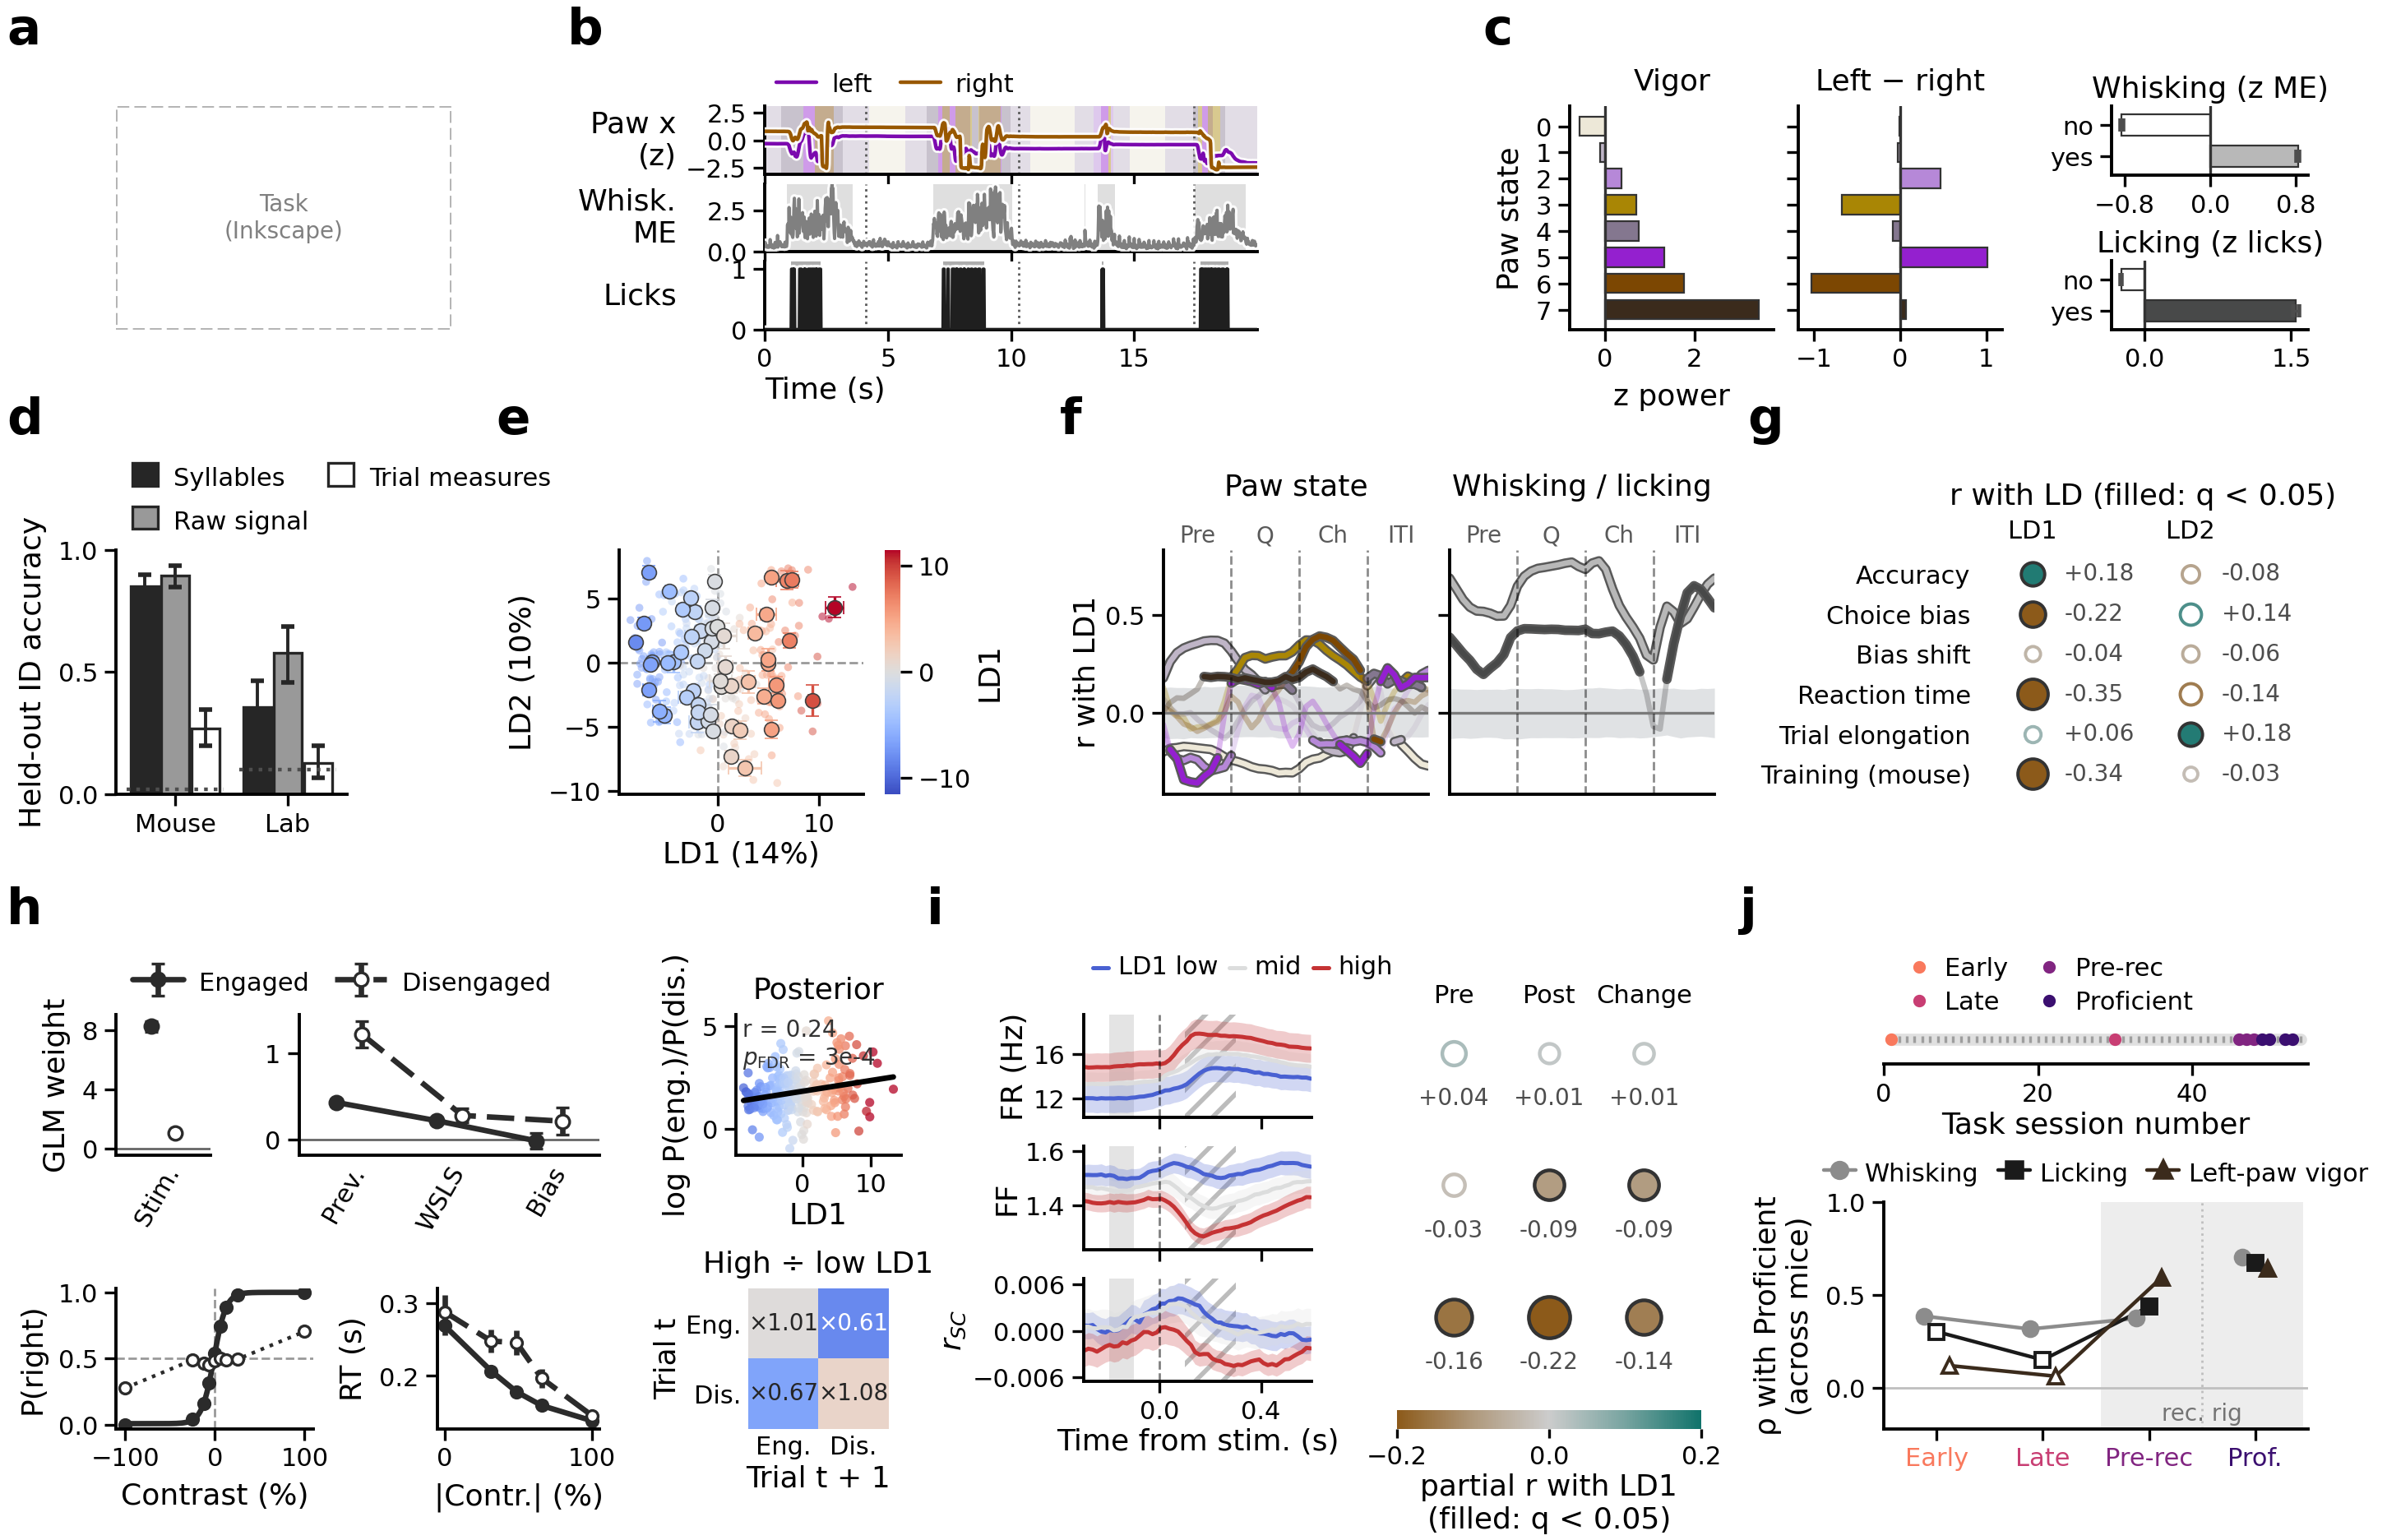

wrote figure_generation/figures/cosyne_figure_12-10-2026.svg


wrote figure_generation/figures/cosyne_figure.pdf


In [9]:
from datetime import date
FIG_H = 4.3
fig = plt.figure(figsize=(fl.FIG_WIDTH, FIG_H))
outer = fig.add_gridspec(3, 1, height_ratios=[1.05, 1.15, 1.95], hspace=0.75,
                         left=0.05, right=0.99, top=0.985, bottom=0.05)
r1 = outer[0].subgridspec(1, 3, width_ratios=[1.5, 2.2, 3.3], wspace=0.6)
r2 = outer[1].subgridspec(1, 4, width_ratios=[1.15, 1.45, 2.75, 1.65], wspace=0.75)
# bottom row: engagement | neural | learning
block = outer[2].subgridspec(1, 3, width_ratios=[3.05, 2.4, 1.65], wspace=0.3)
r3 = [r2[3], block[0]]
r4 = [block[1], block[2]]

def draw_a(fig, spec):
    ax = fig.add_subplot(spec); ax.set_axis_off()
    ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, fill=False, ec='0.7', ls='--', lw=0.7))
    ax.text(0.5, 0.5, 'Task\n(Inkscape)', ha='center', va='center', transform=ax.transAxes,
            fontsize=plt.rcParams['font.size'] * 0.8, color='0.5')
    return [ax]

def draw_c(fig, spec):
    # fig_segmentation's three channels, with short y labels so they fit the row's height
    axes = SEG['draw_F'](fig, spec)
    for ax, lab in zip(axes, ['Paw x\n(z)', 'Whisk.\nME', 'Licks']):
        ax.set_ylabel(lab, rotation=0, ha='right', va='center', labelpad=2)
    fig.align_ylabels(axes)
    axes[-1].set_xlabel('Time (s)', loc='left', labelpad=1)   # left-aligned: clear of the next row's letter
    return axes

def draw_gpanel(fig, spec):
    axes = LD['draw_B'](fig, spec, legend=False)
    # the epoch names: too long for their quarter of each axis, so slanted underneath (the x axis has no ticks)
    full = {'Pre-Q': 'Pre-qui.', 'Quiesc.': 'Quiescence', 'Choice': 'Choice', 'ITI': 'ITI'}
    for ax in axes:
        for t in ax.texts:
            if t.get_text() in full:
                t.set_text(full[t.get_text()]); t.set_y(-0.03); t.set_rotation(35)
                t.set_ha('right'); t.set_va('top'); t.set_rotation_mode('anchor')
        ax.set_title(ax.get_title(), pad=3)
    axes[0].set_ylabel('r with LD1', labelpad=1)
    return axes

def draw_f(fig, spec):
    # mice in the LD1-LD2 plane, with the LD1 colour bar for the whole figure beside it
    g = spec.subgridspec(1, 2, width_ratios=[1, 0.06], wspace=0.08)
    if LDA_NS is None:
        return mock_panel(fig, g[0], 'fig_ld1', 'def draw_A', 'f: LD1 x LD2')
    ax = LDA_NS['draw_A'](fig, g[0])[0]
    ax.set_xlabel(f"LD1 ({100 * LDA_NS['AXIS_SHARE'][0]:.0f}%)", labelpad=1)
    mm = LDA_NS['lda'].groupby('mouse_name')['LD1'].mean().to_numpy()
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=ps.ld1_norm(mm), cmap=ps.LD1_CMAP), cax=fig.add_subplot(g[1]))
    cb.set_label('LD1', labelpad=1); cb.outline.set_visible(False)
    return [ax, cb.ax]

def normalise_fonts(fig, tick=5.5, label=6.5, title=6.5, legend=5.5, note=5.0):
    # one type scale for the whole figure: every source notebook sized its own panels for a larger cell
    for ax in fig.axes:
        ax.tick_params(labelsize=tick)
        ax.xaxis.label.set_fontsize(label); ax.yaxis.label.set_fontsize(label)
        ax.title.set_fontsize(title)
        for t in ax.texts:
            t.set_fontsize(note)
        leg = ax.get_legend()
        if leg is not None:
            for t in leg.get_texts():
                t.set_fontsize(legend)
            if leg.get_title() is not None:
                leg.get_title().set_fontsize(legend)

panels = {
    'a': draw_a(fig, r1[0]),
    'c': draw_c(fig, r1[1]) if SEG else mock_panel(fig, r1[1], 'fig_segmentation', 'def draw_F', 'segmentations'),
    'b': draw_b(fig, r1[2]),
    'e': draw_e(fig, r2[0]),
    'f': draw_f(fig, r2[1]),
    'g': draw_gpanel(fig, r2[2]) if LD else mock_panel(fig, r2[2], 'fig_ld1', 'def draw_B', 'syllable use along LD1'),
    'h': draw_hmap(fig, r3[0]), 'i': draw_engagement(fig, r3[1]), 'j': draw_h(fig, r4[0]), 'k': draw_k(fig, r4[1]),
}
normalise_fonts(fig)
# printed letters follow reading order (the keys are the drawing functions' historical names)
LETTERS = dict(zip(['a', 'c', 'b', 'e', 'f', 'g', 'h', 'i', 'j', 'k'], 'abcdefghij'))
fl.place_letters(fig, panels, rows=['acb', 'efgh', 'ijk'], left='aei', letters=LETTERS)
plt.show()

OUT_DIR = FIGDIR / 'figures'
OUT_DIR.mkdir(exist_ok=True)
for path in [OUT_DIR / f"{FIG}_{date.today().strftime('%d-%m-%Y')}.svg", OUT_DIR / f'{FIG}.pdf']:
    fig.savefig(path)
    print('wrote', path.relative_to(PI))